# 35 — Comparing the four trained CNN variants and choosing the demo model

**Which CNN should we use for the demo?** This notebook compares the
four saved notebook-29 variants, with the mathematical matcher as a reference.
It shows physical agreement, training curves and actual returned terrain.

One architecture was trained four times: two lunar data views × two sampling
policies. We use this development comparison to choose **full-context +
region-balanced** for [notebook 36's demo](36_slope_and_relative_elevation_demo.ipynb).
It ties for the highest top-five physical-match rate and has lower slope
and height-range errors than the other tied model. Another variant has
the lowest height-range error overall, so the choice reflects these
tradeoffs rather than a win on every measure.

**Read the main table and plots below for results.** A compatible result meets
declared physical limits; it is not a verified mission analog. No independent
relevance ratings exist, and the explored holdout regions are development
data. These comparisons cannot establish general matching accuracy.

We reuse the **original four-rotation embeddings for every variant**, with
each model's saved training scaler. This isolates the existing variant
comparison. Notebook 34's eight-orientation/reflection cache covers one
variant and is not mixed into these results. No training, downloads, new
normalization or access to proposed reserve regions occurs.

In [1]:
# ruff: noqa: E402
# Repository discovery must precede local imports when running from a notebook folder.
import hashlib
import json
import sys
from datetime import UTC, datetime
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from matplotlib.figure import Figure

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "outline.md").exists())
sys.path.insert(0, str(ROOT))
from notebooks.modeling.terrain_similarity.candidate_coverage import candidate_coverage
from notebooks.modeling.terrain_similarity.model_comparison import (
    align_common_locations, summarize_comparison,
)
from notebooks.modeling.terrain_similarity.similarity_cnn import cosine_top_k
from notebooks.modeling.terrain_similarity.similarity_experiment import evaluation_queries
from notebooks.modeling.terrain_similarity.terrain_dataset import FEATURES, validate_config
from notebooks.modeling.terrain_similarity.terrain_learning import rank_candidates
from notebooks.shared.analysis_artifacts import publish_analysis
from notebooks.shared.inspection import check_input, file_hash, verify_run

SOURCE = ROOT / "data/processed/terrain_similarity_cnn/20261101T082707986851Z_5413e6"
DATASET = ROOT / "data/processed/terrain_learning_readiness/20261101T064233918547Z_4a05ac"
NOTEBOOK = ROOT / "notebooks/modeling/terrain_similarity/35_four_model_comparison.ipynb"
SEED = 36
QUERIES_PER_REGION = 32
VIEWS = ["full_context", "image_supported"]
SAMPLING = ["region_balanced", "count_weighted"]
MODEL_LABELS = {
    "full_context__region_balanced": "Full / balanced (demo)",
    "full_context__count_weighted": "Full / count-weighted",
    "image_supported__region_balanced": "Supported / balanced",
    "image_supported__count_weighted": "Supported / count-weighted",
}
METHOD_LABELS = {**MODEL_LABELS, "physical": "Mathematical reference"}
METHODS = list(METHOD_LABELS)
COLORS = ["#007b83", "#4b9eb2", "#a6611a", "#dfb366", "#666666"]
CHECK_FEATURES = ["central_relief_m", "slope_p90_deg", "local_sd_median_m"]
THRESHOLDS = {"tight": .5, "nominal": 1., "wide": 2.}
OUT = ROOT / "data/processed/analysis" / (
    "four-model-comparison-" + datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ"))
OUT.mkdir(parents=True, exist_ok=False)
expected = {**verify_run(SOURCE), **verify_run(DATASET)}
evidence = {str(p.resolve()): file_hash(p) for p in [
    SOURCE / "provenance.json", DATASET / "provenance.json",
    *(ROOT / "notebooks" / name for name in [
        "modeling/terrain_similarity/model_comparison.py",
        "modeling/terrain_similarity/candidate_coverage.py",
        "modeling/terrain_similarity/similarity_cnn.py",
        "modeling/terrain_similarity/similarity_experiment.py",
        "modeling/terrain_similarity/terrain_dataset.py",
        "modeling/terrain_similarity/terrain_learning.py",
        "shared/retrieval_analysis.py", "shared/inspection.py", "shared/analysis_artifacts.py",
    ]),
]}
book = nbformat.read(NOTEBOOK, as_version=4)
source_text = "\n".join(cell.source for cell in book.cells)
provenance: dict[str, Any] = {
    "status": "running", "source": SOURCE.relative_to(ROOT).as_posix(),
    "dataset": DATASET.relative_to(ROOT).as_posix(), "seed": SEED,
    "notebook_source_sha256": hashlib.sha256(source_text.encode()).hexdigest(),
    "queries_per_region": QUERIES_PER_REGION, "inference": "original four rotations, no reflections",
    "threshold_multipliers": THRESHOLDS, "aggregation": "query means within regions; equal-region means",
    "role": "matched development diagnostic; no independent relevance validation or model promotion",
    "reserves_opened": False, "python": sys.version,
    "numpy": np.__version__, "pandas": pd.__version__, "torch": str(torch.__version__),
}
(OUT / "provenance.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")

def consumed(path: Path) -> Path:
    return check_input(path, expected, evidence)

def save_figure(fig: Figure, name: str) -> None:
    fig.savefig(OUT / f"{name}.png", dpi=130, bbox_inches="tight")
    fig.savefig(OUT / f"{name}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .2})
print("Saved training run:", SOURCE.relative_to(ROOT).as_posix())

Saved training run: data/processed/terrain_similarity_cnn/20261101T082707986851Z_5413e6


## What changes between the four versions?

- **Full context:** more lunar terrain, including reconstructed areas with
  weaker image support. **Image supported:** a smaller, stricter collection.
- **Region balanced:** regions get equal sampling probability. **Count
  weighted:** regions with more eligible patches get more training draws.

Architecture, seed and training budget are held fixed. Each variant retains
the scaler fitted on its own training data. Training loss and recorded time
describe training; neither establishes retrieval quality.

In [2]:
dataset_record = json.loads((DATASET / "provenance.json").read_text(encoding="utf-8"))
source_record = json.loads((SOURCE / "provenance.json").read_text(encoding="utf-8"))
validate_config(dataset_record["config"])
assert dataset_record["config"]["patch_size_m"] == 960
assert source_record["config"]["dataset_run"] == DATASET.relative_to(ROOT).as_posix()
assert set(source_record["config"]["views"]) == set(VIEWS)
assert set(source_record["config"]["sampling_modes"]) == set(SAMPLING)
patches = pd.read_csv(consumed(DATASET / "patches.csv"))
assert patches.patch_id.is_unique
roles = {(r["body"], r["region"]): r["fold"] for r in dataset_record["config"]["regions"]}
for item in pd.DataFrame(patches[["body", "region", "role", "fold"]].drop_duplicates()).to_dict("records"):
    assert item["role"] == "development" and roles.get((item["body"], item["region"])) == item["fold"]

catalogues = {view: patches.loc[(patches.body == "earth") | (patches.view == view)].copy()
              for view in VIEWS}
aligned = align_common_locations(catalogues)
bank = aligned["full_context"].copy()
for view in VIEWS:
    np.testing.assert_allclose(aligned[view][FEATURES], bank[FEATURES], rtol=0, atol=1e-6)
    for field in ["left", "bottom", "right", "top", "size_m", "spacing_m", "context_m", "crs_wkt"]:
        np.testing.assert_array_equal(aligned[view][field], bank[field])

vectors: dict[str, np.ndarray] = {}
histories: dict[str, pd.DataFrame] = {}
model_rows = []
for view in VIEWS:
    for sampling in SAMPLING:
        method = f"{view}__{sampling}"
        folder = SOURCE / view / sampling
        checkpoint = consumed(folder / "model.pt")
        preprocessing = json.loads(consumed(folder / "preprocessing.json").read_text(encoding="utf-8"))
        assert preprocessing["view"] == view
        assert preprocessing["dataset_run"] == DATASET.relative_to(ROOT).as_posix()
        assert preprocessing["inference"] == "Mean of four 90-degree rotation embeddings, then L2 normalization"
        scaler = json.loads(consumed(DATASET / f"scaler_{view}.json").read_text(encoding="utf-8"))
        assert preprocessing["scaler"] == scaler
        with np.load(consumed(folder / "embeddings.npz"), allow_pickle=False) as archive:
            ids = pd.Index(archive["patch_ids"].astype(str))
            saved_vectors = archive["cnn"].copy()
        assert ids.is_unique and set(ids) == set(catalogues[view].patch_id)
        assert saved_vectors.shape == (len(ids), 64)
        positions = ids.get_indexer(aligned[view].patch_id)
        assert (positions >= 0).all()
        vectors[method] = saved_vectors[positions]
        assert np.isfinite(vectors[method]).all()
        np.testing.assert_allclose(np.linalg.norm(vectors[method], axis=1), 1., atol=1e-5)
        history = pd.read_csv(consumed(folder / "training_history.csv"))
        assert history.epoch.tolist() == list(range(1, source_record["config"]["epochs"] + 1))
        histories[method] = history
        model_rows.append({
            "model": MODEL_LABELS[method], "lunar_view": view, "sampling": sampling,
            "lunar_train_patches": int(((catalogues[view].body == "moon") & (catalogues[view].fold == "train")).sum()),
            "earth_train_patches": int(((catalogues[view].body == "earth") & (catalogues[view].fold == "train")).sum()),
            "epochs": len(history), "final_training_loss": float(history.loss.iloc[-1]),
            "recorded_training_seconds": float(history.seconds.sum()),
            "checkpoint_sha256": evidence[str(checkpoint.resolve())],
        })
models = pd.DataFrame(model_rows)
models.to_csv(OUT / "model_inventory.csv", index=False)
display(models.drop(columns="checkpoint_sha256").round(3))

,model,lunar_view,sampling,lunar_train_patches,earth_train_patches,epochs,final_training_loss,recorded_training_seconds
0,Full / balanced (demo),full_context,region_balanced,2685,2615,10,1.831,6.065
1,Full / count-weighted,full_context,count_weighted,2685,2615,10,1.870,4.574
2,Supported / balanced,image_supported,region_balanced,946,2615,10,1.856,4.353
3,Supported / count-weighted,image_supported,count_weighted,946,2615,10,1.908,3.960


## Give every model the same question

The original notebook-29 samples differ between lunar views. Here we first
intersect their **eligible locations**, then draw up to 32 queries per region
with a fixed seed. Every model receives the same query locations and candidate
locations. Their terrain descriptors and footprints are checked for equality.

This deliberately restricts evaluation to image-supported lunar locations.
It cannot assess the extra coverage offered by full-context terrain. Each
model still uses its own saved preprocessing and learned weights.

We keep three development cases separate: training query → holdout candidates;
holdout query → training candidates; holdout query → holdout candidates.
We also keep Moon → Earth and Earth → Moon separate. The last case in
Moon → Earth uses **one lunar query region and one Earth candidate region**,
so it is not evidence of generalization across many new regions.

In [3]:
query_indices = evaluation_queries(bank, QUERIES_PER_REGION, SEED)
queries = bank.iloc[query_indices].copy()
cohort = bank[["location_id", "body", "region", "fold", *FEATURES]].copy()
for view in VIEWS:
    cohort[f"{view}_patch_id"] = aligned[view].patch_id.to_numpy()
cohort.to_csv(OUT / "shared_locations.csv", index=False)
queries.to_csv(OUT / "evaluation_queries.csv", index=False)
inventory = bank.groupby(["body", "fold"], as_index=False).agg(
    eligible_locations=("location_id", "size"), regions=("region", "nunique"))
query_counts = queries.groupby(["body", "fold"], as_index=False).agg(queries=("patch_id", "size"))
display(inventory.merge(query_counts, on=["body", "fold"], validate="one_to_one"))
original_queries = {}
for view in VIEWS:
    original = pd.read_csv(consumed(SOURCE / view / "evaluation_queries.csv"))
    original = original.merge(patches[["patch_id", "location_id"]], on="patch_id", validate="one_to_one")
    original_queries[view] = set(original.loc[(original.body == "moon") & (original.fold == "holdout"), "location_id"])
print("Shared lunar holdout queries in the original samples:", len(set.intersection(*original_queries.values())))
print("New matched lunar holdout queries:", int(((queries.body == "moon") & (queries.fold == "holdout")).sum()))
print("Every model uses the same locations and candidate pools below.")

,body,fold,eligible_locations,regions,queries
0,earth,holdout,3078,1,32
1,earth,train,2615,4,128
2,moon,holdout,68,1,32
3,moon,train,946,6,192


Shared lunar holdout queries in the original samples: 5
New matched lunar holdout queries: 32
Every model uses the same locations and candidate pools below.


## What counts as a physical match here?

Reuse notebook 32's declared limits: relief within **max(10 m, 25% of query
relief)**, steep-end slope (P90) within **3°**, and local height variation
within **max(2 m, 25% of the query value)**. All three must pass together.
Half and twice these limits provide a sensitivity check; no threshold is tuned.

**Top-five hit rate** is the fraction of queries with at least one compatible
candidate in the first five. Queries without any compatible candidate stay
in the denominator. Availability is reported alongside hits. We also report
the first result's height, slope and local-variation errors in physical units.

Averages first give queries equal weight within each region, then give regions
equal weight. The mathematical reference directly uses related descriptors:
this evaluates physical agreement, not independently judged terrain relevance.

### Main comparison: Moon → Earth, both sides held out for development

,Queries,Query regions,Available (%),Top-1 hit (%),Top-5 hit (%),Relief error (m),Slope error (deg),Local variation error (m)
Model,,,,,,,,
Full / balanced (demo),32,1,100.0,34.38,56.25,74.39,2.77,6.12
Full / count-weighted,32,1,100.0,25.00,56.25,77.02,3.59,5.75
Supported / balanced,32,1,100.0,15.62,40.62,107.96,3.59,8.24
Supported / count-weighted,32,1,100.0,6.25,50.00,46.96,5.25,4.71
Mathematical reference,32,1,100.0,81.25,100.00,26.59,2.12,2.14


Errors are equal-region means of first-result absolute differences. Smaller is better; hits: larger is better.


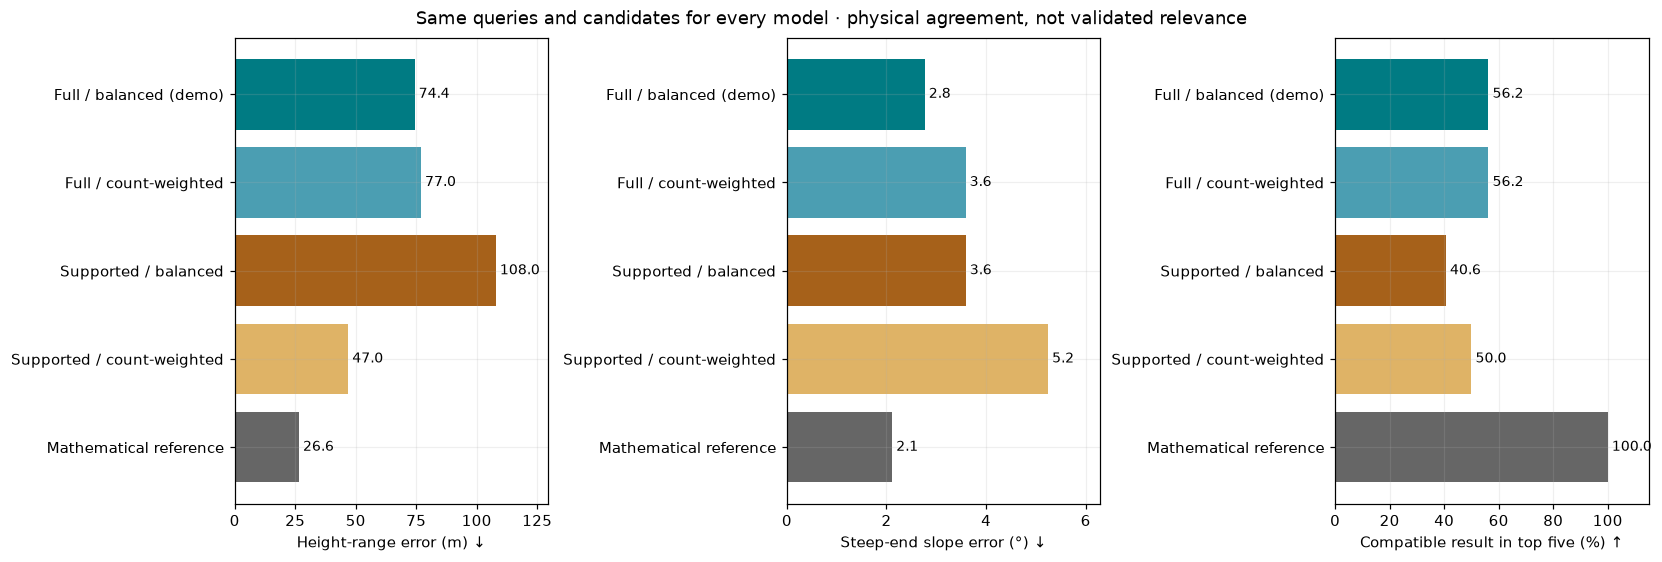

In [4]:
descriptors = bank[FEATURES].to_numpy(dtype=float)
physical = bank[CHECK_FEATURES].to_numpy(dtype=float)
assert np.isfinite(descriptors).all() and (physical >= 0).all()
result_rows = []
ranking_rows = []
for query_index in query_indices:
    qi = int(query_index)
    query = bank.iloc[qi]
    other_body = "earth" if query.body == "moon" else "moon"
    cases = [("heldout_candidates", "holdout")] if query.fold == "train" else [
        ("heldout_queries", "train"), ("both_heldout", "holdout")]
    limits = np.array([max(10., .25 * physical[qi, 0]), 3., max(2., .25 * physical[qi, 2])])
    for case, candidate_fold in cases:
        pool = np.flatnonzero((bank.body.to_numpy() == other_body) & (bank.fold.to_numpy() == candidate_fold))
        candidate_ids = bank.iloc[pool].patch_id.tolist()
        assert len(pool) >= 5
        rankings = {method: cosine_top_k(embedding[qi], embedding[pool], candidate_ids, len(pool))
                    for method, embedding in vectors.items()}
        rankings["physical"] = rank_candidates(descriptors[qi], descriptors[pool], candidate_ids, len(pool))
        for method, (order, scores) in rankings.items():
            errors = np.abs(physical[pool[order[0]]] - physical[qi])
            for threshold, multiplier in THRESHOLDS.items():
                stats = candidate_coverage(physical[qi], physical[pool], limits * multiplier, order)
                result_rows.append({
                    "method": method, "direction": query.body + "_to_" + other_body,
                    "case": case, "threshold": threshold, "query_id": query.patch_id,
                    "query_region": query.region, "candidate_count": len(pool), **stats,
                    "available": int(stats["compatible_count"] > 0),
                    "top1_relief_error_m": float(errors[0]), "top1_slope_error_deg": float(errors[1]),
                    "top1_local_sd_error_m": float(errors[2]),
                })
            for rank, (position, score) in enumerate(zip(order[:5], scores[:5], strict=True), 1):
                ranking_rows.append({
                    "method": method, "direction": query.body + "_to_" + other_body, "case": case,
                    "query_id": query.patch_id, "candidate_id": candidate_ids[int(position)],
                    "rank": rank, "score": float(score),
                    "score_kind": "discrepancy_lower_better" if method == "physical" else "cosine_higher_better",
                })
results = pd.DataFrame(result_rows)
top_five = pd.DataFrame(ranking_rows)
identity = ["direction", "case", "threshold", "query_id"]
assert (results.groupby(identity).method.nunique() == len(METHODS)).all()
assert (results.groupby(identity).compatible_count.nunique() == 1).all()
assert (results.groupby(identity).candidate_count.nunique() == 1).all()
regional, macro = summarize_comparison(results)
results.to_csv(OUT / "query_metrics.csv", index=False)
top_five.to_csv(OUT / "top_five.csv", index=False)
regional.to_csv(OUT / "regional_summary.csv", index=False)
macro.to_csv(OUT / "region_macro_summary.csv", index=False)
primary = macro.loc[(macro.direction == "moon_to_earth") & (macro.case == "both_heldout")
                    & (macro.threshold == "nominal")].set_index("method").loc[METHODS]
summary = primary[["query_count", "query_region_count", "available", "top1_hit", "top5_hit",
                   "top1_relief_error_m", "top1_slope_error_deg", "top1_local_sd_error_m"]].copy()
summary.index = pd.Index([METHOD_LABELS[str(method)] for method in summary.index], name="Model")
summary = summary.rename(columns={
    "query_count": "Queries", "query_region_count": "Query regions", "available": "Available (%)",
    "top1_hit": "Top-1 hit (%)", "top5_hit": "Top-5 hit (%)", "top1_relief_error_m": "Relief error (m)",
    "top1_slope_error_deg": "Slope error (deg)", "top1_local_sd_error_m": "Local variation error (m)",
})
summary[["Available (%)", "Top-1 hit (%)", "Top-5 hit (%)"]] *= 100
display(Markdown("### Main comparison: Moon → Earth, both sides held out for development"))
display(summary.round(2))
print("Errors are equal-region means of first-result absolute differences. Smaller is better; hits: larger is better.")
fig, axes = plt.subplots(1, 3, figsize=(15, 5), layout="constrained")
for ax, metric, title, scale in zip(axes,
    ["top1_relief_error_m", "top1_slope_error_deg", "top5_hit"],
    ["Height-range error (m) ↓", "Steep-end slope error (°) ↓", "Compatible result in top five (%) ↑"],
    [1., 1., 100.], strict=True):
    values = primary[metric].to_numpy(dtype=float) * scale
    ax.barh(range(len(METHODS)), values, color=COLORS)
    ax.set_yticks(range(len(METHODS)), [METHOD_LABELS[m] for m in METHODS])
    ax.invert_yaxis()
    ax.set(xlabel=title, xlim=(0, 115 if scale == 100 else max(values) * 1.2))
    for row, value in enumerate(values):
        ax.text(value + max(values.max(), 1.) * .015, row, f"{value:.1f}", va="center", fontsize=9)
fig.suptitle("Same queries and candidates for every model · physical agreement, not validated relevance")
save_figure(fig, "main_comparison")

## Training curves and sensitivity

Losses measure the rotation-pair training task. Different views and samplers
change that task's data distribution, so the lowest loss is not a winner.
The hit-rate curves show whether changing the physical limits changes the
comparison. They also expose candidate shortages in reverse retrieval.

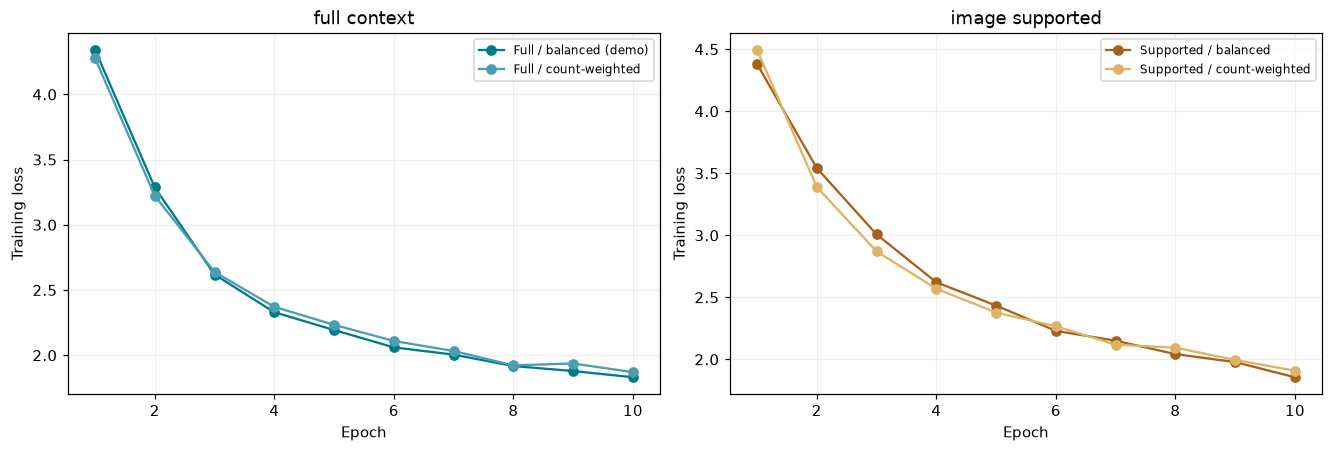

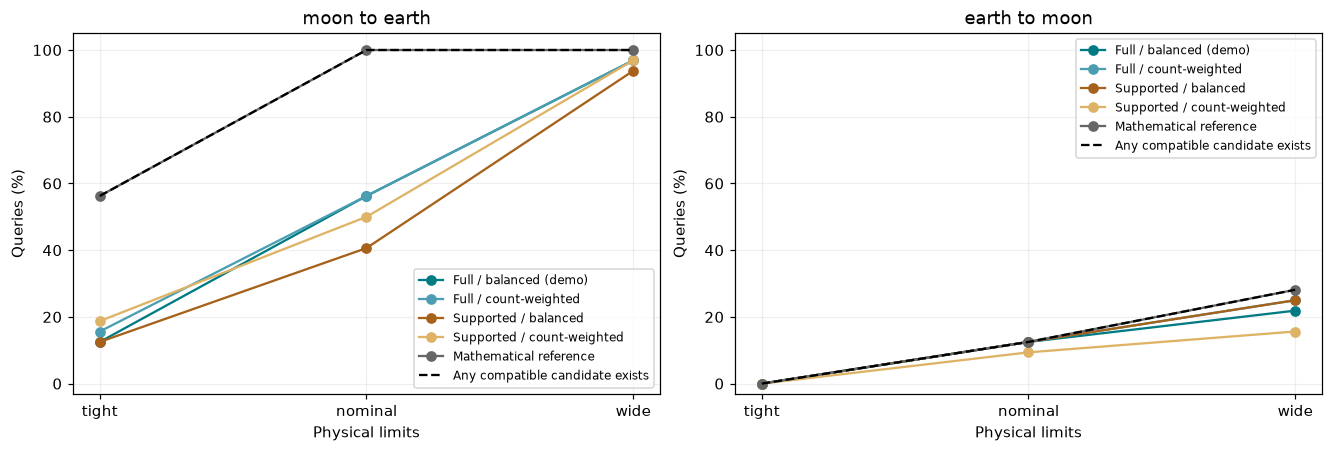

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, view in zip(axes, VIEWS, strict=True):
    for method, history in histories.items():
        if method.startswith(view + "__"):
            ax.plot(history.epoch, history.loss, marker="o", label=MODEL_LABELS[method], color=COLORS[METHODS.index(method)])
    ax.set(title=view.replace("_", " "), xlabel="Epoch", ylabel="Training loss")
    ax.legend(fontsize=8)
save_figure(fig, "training_curves")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, direction in zip(axes, ["moon_to_earth", "earth_to_moon"], strict=True):
    rows = macro.loc[(macro.direction == direction) & (macro.case == "both_heldout")]
    for method, color in zip(METHODS, COLORS, strict=True):
        values = rows.loc[rows.method == method].set_index("threshold").loc[list(THRESHOLDS)]
        ax.plot(list(THRESHOLDS), 100 * values.top5_hit, marker="o", color=color, label=METHOD_LABELS[method])
    availability = rows.loc[rows.method == METHODS[0]].set_index("threshold").loc[list(THRESHOLDS)]
    ax.plot(list(THRESHOLDS), 100 * availability.available, "k--", label="Any compatible candidate exists")
    ax.set(title=direction.replace("_", " "), ylabel="Queries (%)", ylim=(-3, 105), xlabel="Physical limits")
    ax.legend(fontsize=8)
save_figure(fig, "threshold_sensitivity")

## Does the comparison change by region or split?

The heatmap uses the six lunar training regions querying held-out Earth
candidates. It complements the one-region lunar holdout result above.
The table includes both directions and all split cases; do not pool them
into one overall score. These regions reuse development data and are not
independent test replications.

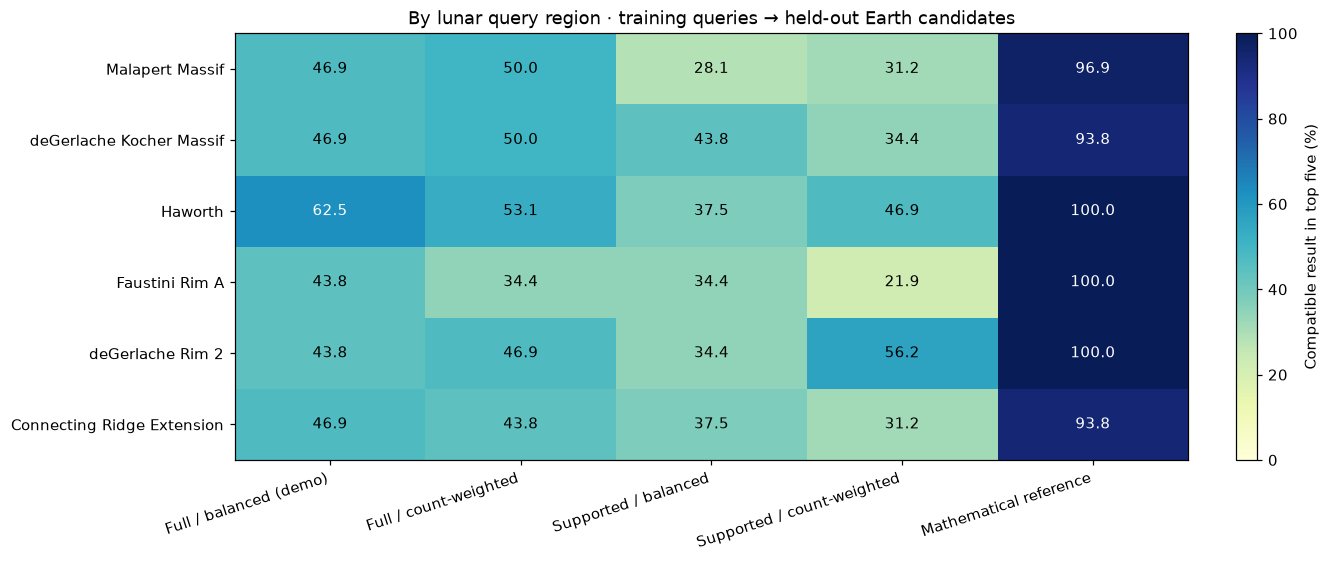

,direction,case,method,query_count,query_region_count,available,top5_hit,top1_relief_error_m,top1_slope_error_deg
0,earth_to_moon,both_heldout,Full / count-weighted,32,1,0.125,0.125,157.233,10.258
3,earth_to_moon,heldout_candidates,Full / count-weighted,128,4,0.016,0.016,222.693,15.177
6,earth_to_moon,heldout_queries,Full / count-weighted,32,1,0.281,0.188,155.033,10.316
9,moon_to_earth,both_heldout,Full / count-weighted,32,1,1.000,0.562,77.022,3.591
12,moon_to_earth,heldout_candidates,Full / count-weighted,192,6,1.000,0.464,73.008,4.054
15,moon_to_earth,heldout_queries,Full / count-weighted,32,1,0.125,0.094,153.695,7.453
18,earth_to_moon,both_heldout,Full / balanced (demo),32,1,0.125,0.125,128.383,8.016
21,earth_to_moon,heldout_candidates,Full / balanced (demo),128,4,0.016,0.016,180.291,11.193
24,earth_to_moon,heldout_queries,Full / balanced (demo),32,1,0.281,0.188,151.920,9.794
27,moon_to_earth,both_heldout,Full / balanced (demo),32,1,1.000,0.562,74.394,2.771


In [6]:
region_rows = regional.loc[(regional.direction == "moon_to_earth") & (regional.case == "heldout_candidates")
                           & (regional.threshold == "nominal")]
heatmap = region_rows.pivot(index="query_region", columns="method", values="top5_hit")[METHODS] * 100
fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")
plot = ax.imshow(heatmap.to_numpy(), vmin=0, vmax=100, cmap="YlGnBu", aspect="auto")
ax.set_xticks(range(len(METHODS)), [METHOD_LABELS[m] for m in METHODS], rotation=18, ha="right")
ax.set_yticks(range(len(heatmap)), [str(name).split("_", 2)[-1].replace("_", " ") for name in heatmap.index])
ax.grid(False)
for row in range(len(heatmap)):
    for col in range(len(METHODS)):
        value = float(heatmap.iloc[row, col])
        ax.text(col, row, f"{value:.1f}", ha="center", va="center", color="white" if value > 60 else "black")
fig.colorbar(plot, ax=ax, label="Compatible result in top five (%)")
ax.set_title("By lunar query region · training queries → held-out Earth candidates")
save_figure(fig, "regional_comparison")
all_cases = macro.loc[macro.threshold == "nominal", [
    "direction", "case", "method", "query_count", "query_region_count", "available", "top5_hit",
    "top1_relief_error_m", "top1_slope_error_deg",
]].copy()
all_cases["method"] = all_cases.method.map(METHOD_LABELS)
display(all_cases.round(3))

## What does each model return for the same terrain?

Three examples come from the shared query sample: Leibnitz, Haworth and
Malapert. For each region, select the query nearest the sample's median
relief, breaking ties by patch ID **before looking at model results**.
Each row shows that query, each CNN's first result and the mathematical
reference's first result. All panels in a row use the same height scale and
960 m ground extent. Maps retain source orientation; rotations are allowed
by the retrieval policy. Colors are not rescaled separately per patch.

These selected examples illustrate results; they do not estimate accuracy.

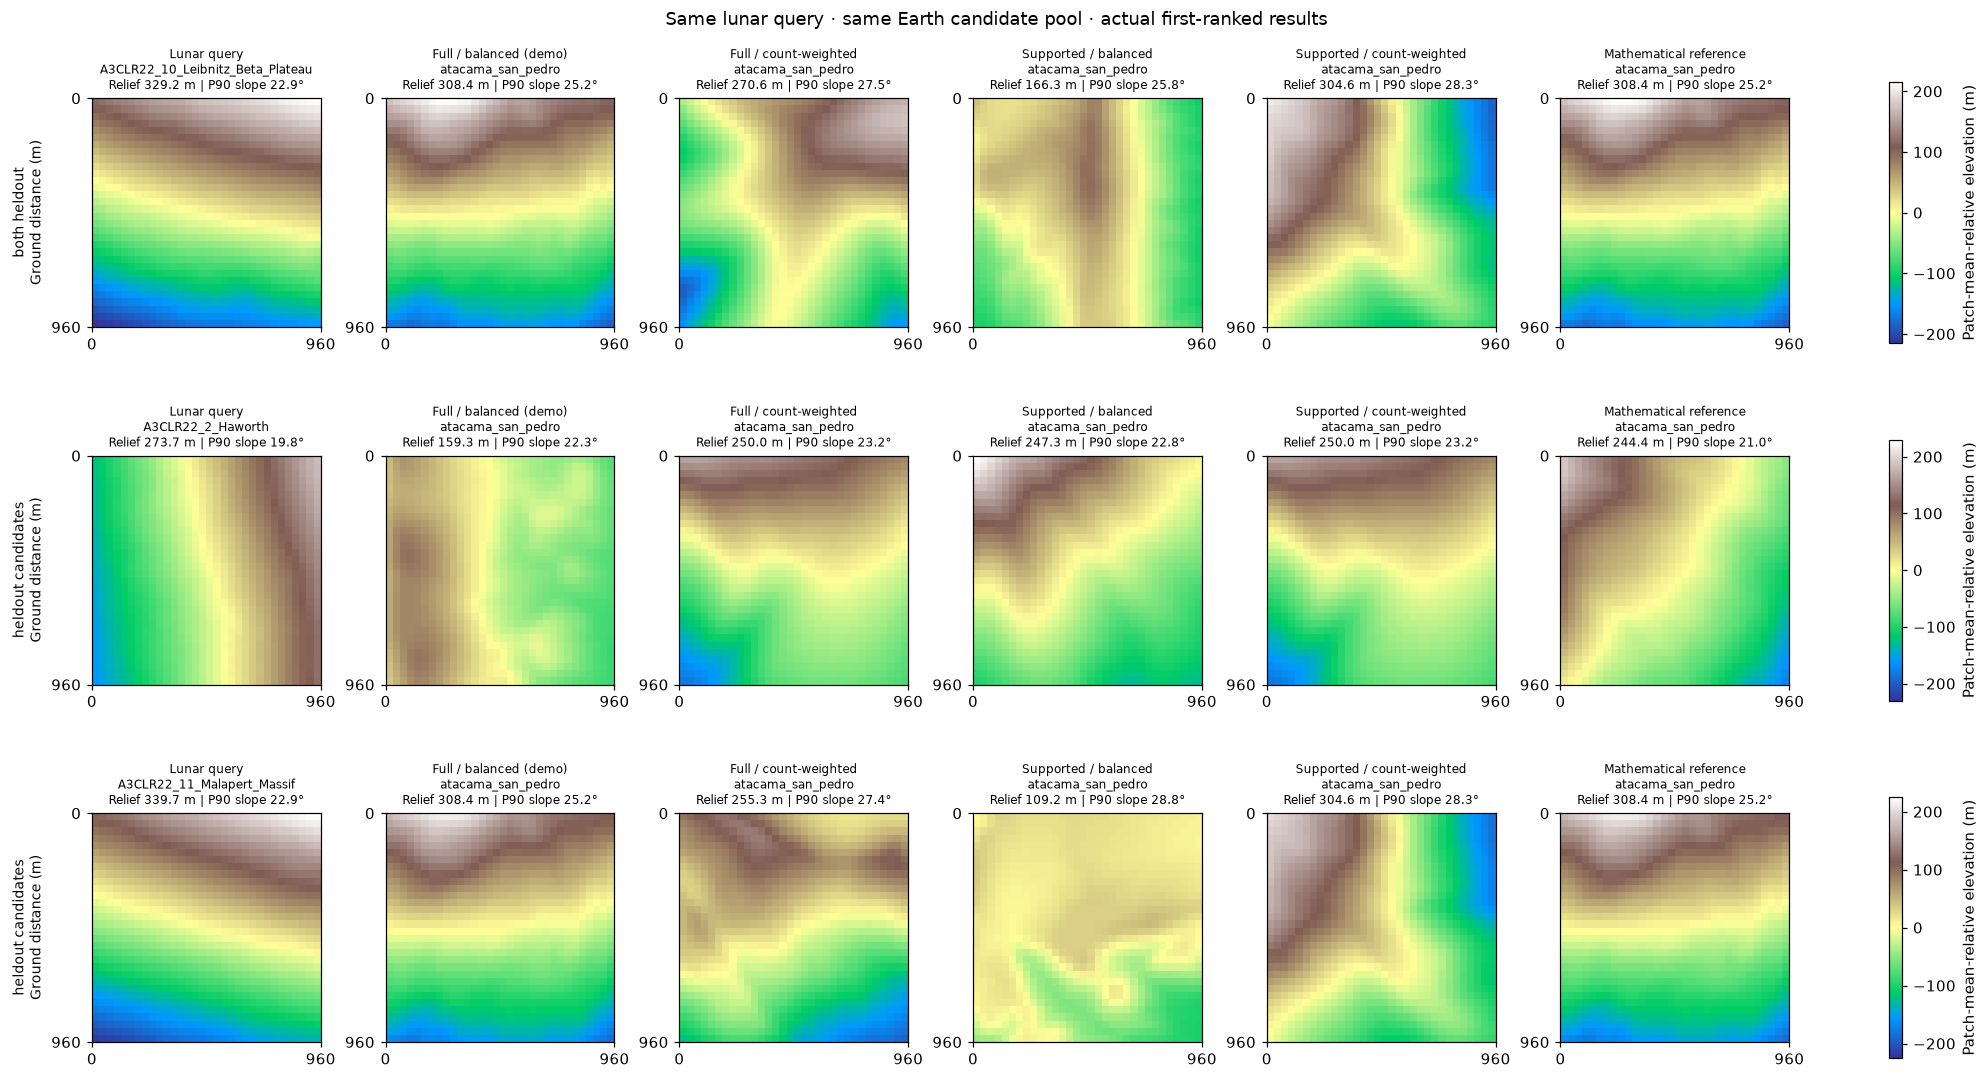

In [7]:
examples = []
for region in ["A3CLR22_10_Leibnitz_Beta_Plateau", "A3CLR22_2_Haworth", "A3CLR22_11_Malapert_Massif"]:
    group = queries.loc[queries.region == region].copy()
    assert len(group)
    group["median_distance"] = np.abs(group.central_relief_m - group.central_relief_m.median())
    examples.append(group.sort_values(["median_distance", "patch_id"]).iloc[0])
tensors: dict[str, np.ndarray] = {}
source_patches = patches.set_index("patch_id", verify_integrity=True)

def terrain_image(patch_id: str) -> np.ndarray:
    patch = source_patches.loc[patch_id]
    shard = str(patch["shard"])
    if shard not in tensors:
        with np.load(consumed(DATASET / shard), allow_pickle=False) as archive:
            tensors[shard] = archive["physical"].copy()
    return tensors[shard][int(patch["tensor_index"]), 0]

fig, axes = plt.subplots(len(examples), 6, figsize=(18, 10), layout="constrained")
example_rows = []
for row, query in enumerate(examples):
    case = "both_heldout" if query.fold == "holdout" else "heldout_candidates"
    selected = top_five.loc[(top_five.query_id == query.patch_id) & (top_five.case == case)
                           & (top_five["rank"] == 1)].set_index("method").loc[METHODS]
    ids = [str(query.patch_id), *selected.candidate_id.astype(str).tolist()]
    images = [terrain_image(patch_id) for patch_id in ids]
    limit = max(float(np.abs(values).max()) for values in images)
    for column, (patch_id, values) in enumerate(zip(ids, images, strict=True)):
        patch = source_patches.loc[patch_id]
        ax = axes[row, column]
        plot = ax.imshow(values, vmin=-limit, vmax=limit, cmap="terrain", extent=(0, 960, 960, 0))
        label = "Lunar query" if column == 0 else METHOD_LABELS[METHODS[column - 1]]
        ax.set_title(f"{label}\n{patch['region']}\nRelief {patch['central_relief_m']:.1f} m | P90 slope {patch['slope_p90_deg']:.1f}°", fontsize=8)
        ax.set_xticks([0, 960])
        ax.set_yticks([0, 960])
        ax.grid(False)
        if column == 0:
            ax.set_ylabel(case.replace("_", " ") + "\nGround distance (m)", fontsize=9)
        else:
            example_rows.append({"query_id": query.patch_id, "case": case,
                                 "method": METHODS[column - 1], "candidate_id": patch_id})
    fig.colorbar(plot, ax=list(axes[row]), label="Patch-mean-relative elevation (m)", shrink=.75)
fig.suptitle("Same lunar query · same Earth candidate pool · actual first-ranked results")
save_figure(fig, "matched_examples")
pd.DataFrame(example_rows).to_csv(OUT / "example_pairs.csv", index=False)

## Choosing the model for notebook 36

The main development comparison supports **full-context + region-balanced** for
the demo. It ties with full-context + count-weighted on the highest top-five
physical-match rate (56.25%). Among those two, it has lower first-result slope
error (2.77° versus 3.59°) and relief error (74.39 m versus 77.02 m).

This choice follows review of these development results. The image-supported,
count-weighted model has the lowest CNN relief error overall (46.96 m), and the
mathematical reference performs better on the main physical checks. We therefore
choose a CNN for the demonstration without declaring an overall mission-analog
winner or treating the choice as an independently validated accuracy result.

Notebook 36 uses the chosen model with notebook 34's rotation/reflection cache.
The comparison here uses four-rotation embeddings for every model, so its
percentages are not measurements of the demo's eight-orientation policy.

In [8]:
cnn_primary = primary.loc[list(MODEL_LABELS)]
findings = []
for metric, label, higher, unit, scale in [
    ("top5_hit", "highest top-five physical hit rate", True, "%", 100.),
    ("top1_relief_error_m", "lowest first-result relief error", False, " m", 1.),
    ("top1_slope_error_deg", "lowest first-result slope error", False, "°", 1.),
]:
    values = cnn_primary[metric].to_numpy(dtype=float)
    best = float(values.max() if higher else values.min())
    names = [MODEL_LABELS[str(name)] for name in cnn_primary.index[np.isclose(values, best, rtol=0, atol=1e-10)]]
    findings.append(f"- **{label.capitalize()}:** {', '.join(names)} — {best * scale:.2f}{unit}.")
answer = "\n".join([
    "On the matched **Moon → Earth, both-held-out development cohort**, among the four CNNs:",
    "", *findings, "",
    "**Demo choice: full-context / region-balanced.** It ties for the highest top-five physical-hit rate "
    "and has lower slope and relief errors than the other tied full-context model on this pinned cohort. "
    "We therefore use it in notebook 36. The supported/count-weighted CNN has lower relief error overall, "
    "and the mathematical reference performs better on these main physical checks. This is a choice "
    "based on development results, not a validated overall winner. Notebook 36 adds reflection "
    "averaging, which this four-rotation comparison does not evaluate.",
])
display(Markdown(answer))
report = "\n".join([
    "# Four-model comparison and demo choice", "", answer, "", "## Main comparison", "",
    "```text", summary.round(2).to_string(), "```", "",
    "Same shared locations and candidate pools; each variant retains its saved scaler. "
    "Original four-rotation embeddings only. No retraining, independent relevance labels or automatic model selection.",
    "", "![Main comparison](main_comparison.png)", "![Training curves](training_curves.png)",
    "![Threshold sensitivity](threshold_sensitivity.png)", "![Regions](regional_comparison.png)",
    "![Examples](matched_examples.png)",
])
(OUT / "REPORT.md").write_text(report + "\n", encoding="utf-8")
provenance["inputs"] = {Path(path).relative_to(ROOT).as_posix(): digest for path, digest in evidence.items()}
provenance["models"] = models.to_dict("records")
provenance["demo_choice"] = {"view": "full_context", "sampling": "region_balanced",
    "basis": "Top-five physical-hit tie; lower slope and relief errors than the other tied model",
    "scope": "Choice after reviewing this development comparison; no independent relevance validation"}
provenance["shared_location_count"] = len(bank)
provenance["query_count"] = len(queries)
provenance["outputs"] = {p.name: file_hash(p) for p in sorted(OUT.iterdir()) if p.is_file() and p.name != "provenance.json"}
provenance["status"] = "publishing"
provenance["completed_utc"] = datetime.now(UTC).isoformat()
(OUT / "provenance.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")
REPORT_OUT = publish_analysis(ROOT, OUT, manifest_name="provenance.json")
print("Reusable tables:", OUT.relative_to(ROOT).as_posix())
print("Report and figures:", REPORT_OUT.relative_to(ROOT).as_posix())

On the matched **Moon → Earth, both-held-out development cohort**, among the four CNNs:

- **Highest top-five physical hit rate:** Full / balanced (demo), Full / count-weighted — 56.25%.
- **Lowest first-result relief error:** Supported / count-weighted — 46.96 m.
- **Lowest first-result slope error:** Full / balanced (demo) — 2.77°.

**Demo choice: full-context / region-balanced.** It ties for the highest top-five physical-hit rate and has lower slope and relief errors than the other tied full-context model on this pinned cohort. We therefore use it in notebook 36. The supported/count-weighted CNN has lower relief error overall, and the mathematical reference performs better on these main physical checks. This is a choice based on development results, not a validated overall winner. Notebook 36 adds reflection averaging, which this four-rotation comparison does not evaluate.

Reusable tables: data/processed/analysis/four-model-comparison-20261104T003113273980Z
Report and figures: reports/analysis/four-model-comparison-20261104T003113273980Z
